# Laboratorio 02: embeddings faciales lineales
**Marianela Díaz · Martina García**  
Machine Learning, UCN · Dr. Juan Bekios Calfa · 2026-02  
Repositorio: https://github.com/Martina-Garcia/ML-2026-02-LAB02

Este notebook complementa el proyecto modular. Compara **PCA, LDA y Fisherfaces**
con **SVM, k-NN y árbol**, en **Olivetti y LFW**, para `d = 10, 20, 30`.
Son 27 combinaciones por dataset y 54 en total. No seleccionamos hiperparámetros
con TEST: presentamos una comparación descriptiva de configuraciones fijadas.

Ejecutar desde la raíz del proyecto, en el entorno de `environment.yml`:
```bash
conda env create -f environment.yml
conda activate lab02-ml-2026-2
jupyter lab
```
La primera ejecución descarga los datasets y compila UMAP; puede tardar varios minutos.
La evidencia adjunta corresponde a la ejecución real de este mismo notebook.

## 1. Pregunta y protocolo
Queremos reconocer una **identidad conocida en una fotografía nueva**. No separamos
por persona: las identidades de TEST también aparecen en TRAIN. Separamos imágenes
con estratificación, `test_size=0.25` y semilla 42; cada combinación usa los mismos
índices. La media, las representaciones y los clasificadores se ajustan solo en TRAIN.

LFW se carga con al menos 20 fotos por identidad y `resize=0.5`. Se retienen hasta
50 identidades de mayor frecuencia; las etiquetas se reindexan conservando nombres
e identificadores originales. N, C, H y W se obtienen de los datos reales.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    raise RuntimeError("Abrir este notebook desde la raíz del proyecto.")
sys.path.insert(0, str(RAIZ))
from src.pipeline import PipelineExperimentos
from src.analisis import AnalisisLaboratorio
from src.config import DIR_RESULTADOS, DIR_FIGURAS

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 10)
print("Python:", sys.version.split()[0])
print("Raíz:", RAIZ.name)


Python: 3.11.18
Raíz: ML-2026-02-LAB02


## 2. Representaciones y clasificadores
Para una imagen fila $x$, PCA calcula $z=(x-\mu)W_{PCA}$ y conserva variación total,
sin usar la etiqueta. LDA utiliza etiquetas y busca separar medias de identidad
respecto de la dispersión dentro de cada clase; con `solver="svd"`, $d\leq C-1$.
Fisherfaces ajusta PCA sobre TRAIN y luego LDA sobre su proyección, con
$d_{LDA}\leq\min(C-1,d_{PCA})$.

En la fábrica entregada **$d_{PCA}=d_{LDA}=d$**. Se mantiene esa decisión para
evaluar el código del equipo. No es una búsqueda exhaustiva del tamaño intermedio
de PCA: con ambas dimensiones iguales, LDA cambia las coordenadas dentro del
subespacio PCA conservado, y puede cambiar su geometría sin agregar información
descartada por PCA. Una extensión sería fijar `d_PCA=100` y validar `d_LDA` dentro
de TRAIN, reajustando ambas etapas en cada fold.

Configuraciones fijas: SVM lineal `C=1`, `probability=True`; k-NN `k=3`, distancia
euclidiana; árbol `max_depth=8`, semilla 42. El tiempo del CSV comprende **fit +
predict del clasificador**; excluye descarga, embedding, mapas y escritura.
Las probabilidades de SVM se calibran internamente; para identificar se usa `predict`.

In [2]:
RECALCULAR = True
if RECALCULAR or not (DIR_RESULTADOS / "resultados_modelos.csv").exists():
    PipelineExperimentos().ejecutar_experimentos()
tabla = pd.read_csv(DIR_RESULTADOS / "resultados_modelos.csv")
assert len(tabla) == 54
assert tabla.groupby("dataset").size().to_dict() == {"lfw": 27, "olivetti": 27}
display(tabla)


== Experimento: Olivetti ==
X (400, 4096)  train (300, 4096)  test (100, 4096)  identidades 40


  pca          d=10  svm    acc=0.860  macro-F1=0.852  0.21s  -> confusion_olivetti_pca_svm_d10.png


  pca          d=10  knn    acc=0.780  macro-F1=0.773  0.01s  -> confusion_olivetti_pca_knn_d10.png


  pca          d=10  arbol  acc=0.310  macro-F1=0.267  0.01s  -> confusion_olivetti_pca_arbol_d10.png


  lda          d=10  svm    acc=0.980  macro-F1=0.980  0.14s  -> confusion_olivetti_lda_svm_d10.png


  lda          d=10  knn    acc=0.990  macro-F1=0.990  0.01s  -> confusion_olivetti_lda_knn_d10.png


... (67 outputs left out)

  mapa tsne_lfw_fisherfaces_d20.png


umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


  mapa umap_lfw_fisherfaces_d20.png
dataset   embedding  d modelo                             parametros  accuracy  macro_f1  tiempo_s
    lfw         pca 10    svm kernel=linear, C=1.0, probability=True    0.3300    0.1730    7.7589
    lfw         pca 10    knn        n_neighbors=3, metric=euclidean    0.1916    0.1259    0.0367
    lfw         pca 10  arbol            max_depth=8, criterion=gini    0.2219    0.0652    0.0647
    lfw         lda 10    svm kernel=linear, C=1.0, probability=True    0.1758    0.1038    0.7385
    lfw         lda 10    knn        n_neighbors=3, metric=euclidean    0.1830    0.0952    0.0657
    lfw         lda 10  arbol            max_depth=8, criterion=gini    0.1196    0.0538    0.0528
    lfw fisherfaces 10    svm kernel=linear, C=1.0, probability=True    0.3329    0.1765    3.5888
    lfw fisherfaces 10    knn        n_neighbors=3, metric=euclidean    0.2161    0.1243    0.0515
    lfw fisherfaces 10  arbol            max_depth=8, criterion=gini    0

,dataset,embedding,d,modelo,parametros,accuracy,macro_f1,tiempo_s
0,olivetti,pca,10,svm,"kernel=linear, C=1.0, probability=True",0.860000,0.851548,0.2109
1,olivetti,pca,10,knn,"n_neighbors=3, metric=euclidean",0.780000,0.772679,0.0064
2,olivetti,pca,10,arbol,"max_depth=8, criterion=gini",0.310000,0.266705,0.0102
3,olivetti,lda,10,svm,"kernel=linear, C=1.0, probability=True",0.980000,0.980000,0.1435
4,olivetti,lda,10,knn,"n_neighbors=3, metric=euclidean",0.990000,0.990000,0.0070
5,olivetti,lda,10,arbol,"max_depth=8, criterion=gini",0.300000,0.302679,0.0119
6,olivetti,fisherfaces,10,svm,"kernel=linear, C=1.0, probability=True",0.900000,0.896190,0.1834
7,olivetti,fisherfaces,10,knn,"n_neighbors=3, metric=euclidean",0.800000,0.779524,0.0074
8,olivetti,fisherfaces,10,arbol,"max_depth=8, criterion=gini",0.440000,0.398790,0.0081
9,olivetti,pca,20,svm,"kernel=linear, C=1.0, probability=True",0.950000,0.946548,0.2162


## 3. Verificar la evidencia y los contratos
Se vuelven a predecir las fotografías de TEST con los modelos guardados y se
recalculan accuracy y macro-F1 para contrastarlas con el CSV. No se reajusta ningún
modelo. Se comprueban dimensiones y valores finitos, y se guardan índices de la
partición, correspondencia de identidades y predicciones por fotografía.

In [3]:
analisis = AnalisisLaboratorio()
resumen = analisis.generar()
display(pd.DataFrame(resumen["versiones"].items(), columns=["Dependencia", "Versión"]))
columnas = ["N", "C", "H", "W", "p", "train", "test", "fotos_min", "fotos_max",
            "intensidad_min", "intensidad_max"]
display(pd.DataFrame(resumen["datasets"]).T[columnas])


LFW: N=2773 C=50 H=62 W=47 fotos/identidad min=22 max=530


,Dependencia,Versión
0,python,3.11.18
1,numpy,2.4.6
2,scipy,1.17.1
3,scikit-learn,1.9.1
4,pandas,3.0.6
5,matplotlib,3.11.2
6,umap-learn,0.6.0
7,streamlit,1.67.0
8,nbclient,0.11.0


,N,C,H,W,p,...,test,fotos_min,fotos_max,intensidad_min,intensidad_max
olivetti,400,40,64,64,4096,...,100,10,10,0.0,1.0
lfw,2773,50,62,47,2914,...,694,22,530,0.0,1.0


## 4. Tablas completas por dataset
Accuracy es la fracción de aciertos. Macro-F1 promedia por identidad con el mismo
peso para todas, lo que resulta especialmente relevante en LFW desbalanceado.
No interpretamos pequeñas diferencias como significativas: hay una sola partición
y no estimamos intervalos de confianza ni variabilidad entre semillas.

In [4]:
for dataset in ["olivetti", "lfw"]:
    display(Markdown(f"### {dataset.upper()}"))
    display(tabla.loc[tabla.dataset == dataset,
                     ["embedding", "d", "modelo", "accuracy", "macro_f1", "tiempo_s"]]
                .sort_values(["embedding", "modelo", "d"]).reset_index(drop=True))


### OLIVETTI

,embedding,d,modelo,accuracy,macro_f1,tiempo_s
0,fisherfaces,10,arbol,0.44,0.398790,0.0081
1,fisherfaces,20,arbol,0.37,0.293364,0.0214
2,fisherfaces,30,arbol,0.29,0.250032,0.0275
3,fisherfaces,10,knn,0.80,0.779524,0.0074
4,fisherfaces,20,knn,0.95,0.937024,0.0072
5,fisherfaces,30,knn,0.95,0.941429,0.0056
6,fisherfaces,10,svm,0.90,0.896190,0.1834
7,fisherfaces,20,svm,0.98,0.978095,0.2063
8,fisherfaces,30,svm,0.96,0.959524,0.2302
9,lda,10,arbol,0.30,0.302679,0.0119


### LFW

,embedding,d,modelo,accuracy,macro_f1,tiempo_s
0,fisherfaces,10,arbol,0.244957,0.120056,0.0778
1,fisherfaces,20,arbol,0.311239,0.172499,0.1425
2,fisherfaces,30,arbol,0.293948,0.152440,0.1084
3,fisherfaces,10,knn,0.216138,0.124279,0.0515
4,fisherfaces,20,knn,0.344380,0.258347,0.0103
5,fisherfaces,30,knn,0.402017,0.308251,0.0144
6,fisherfaces,10,svm,0.332853,0.176450,3.5888
7,fisherfaces,20,svm,0.438040,0.320795,3.0703
8,fisherfaces,30,svm,0.484150,0.395485,3.1451
9,lda,10,arbol,0.119597,0.053752,0.0528


## 5. Varianza acumulada y eigenfaces
La curva utiliza solo TRAIN. Más varianza retenida no equivale automáticamente a
mejor reconocimiento. Las eigenfaces representan pesos, no identidades nuevas.

### OLIVETTI

,d,Varianza retenida
0,10,0.655289
1,20,0.765428
2,30,0.821762


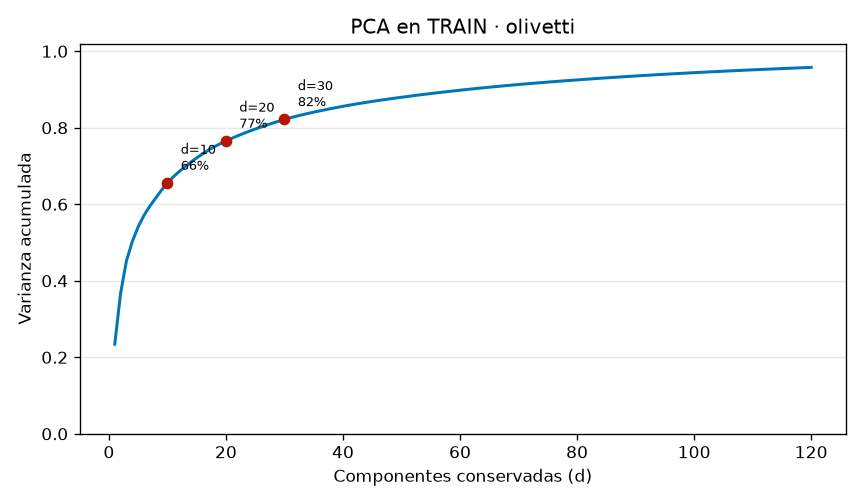

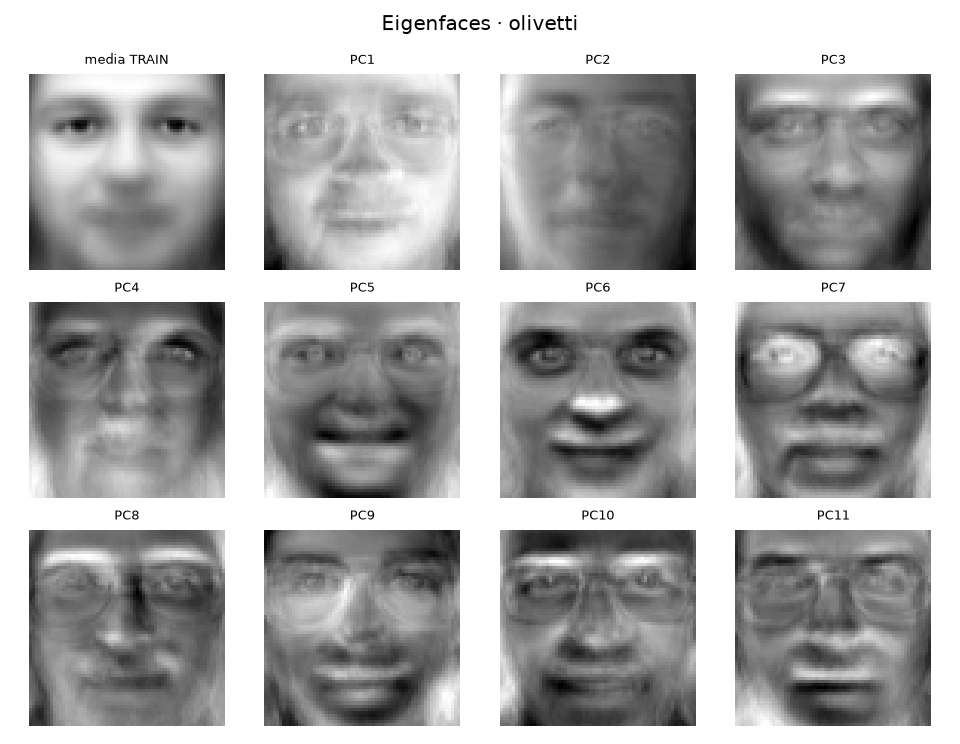

### LFW

,d,Varianza retenida
0,10,0.622759
1,20,0.724147
2,30,0.774517


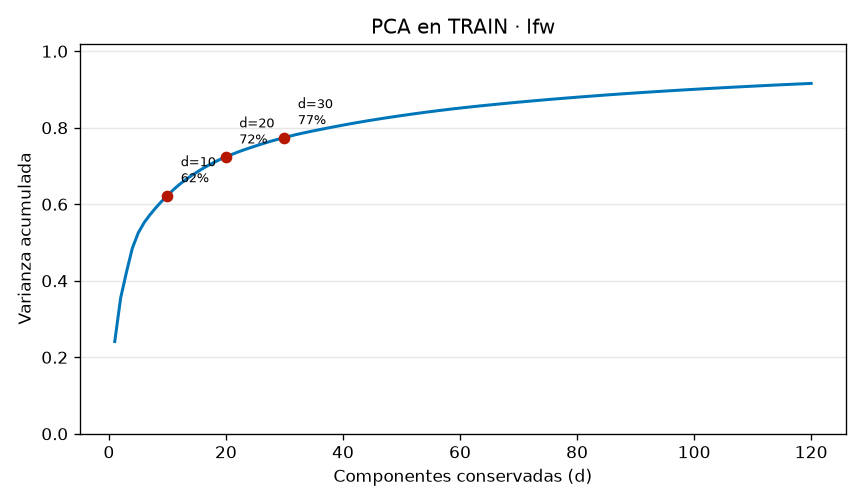

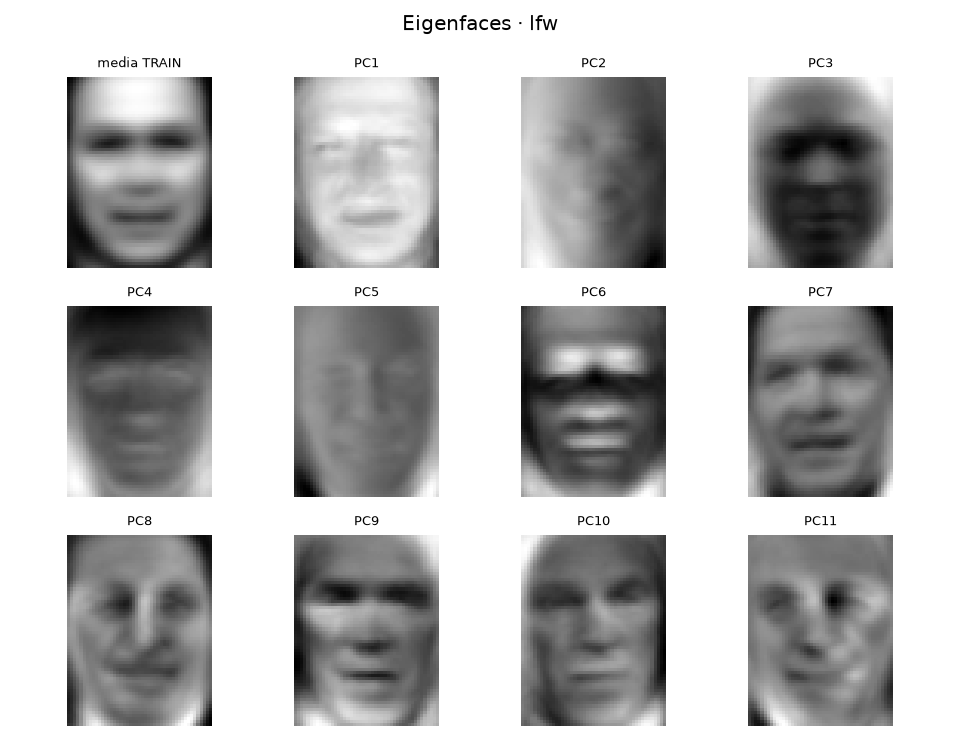

In [5]:
for dataset in ["olivetti", "lfw"]:
    display(Markdown(f"### {dataset.upper()}"))
    display(pd.DataFrame(resumen["datasets"][dataset]["varianza"].items(),
                         columns=["d", "Varianza retenida"]))
    display(Image(filename=str(DIR_FIGURAS / f"curva_pca_{dataset}.png"), width=750))
    display(Image(filename=str(DIR_FIGURAS / f"eigenfaces_{dataset}.png"), width=750))


## 6. t-SNE y UMAP: exploración de TRAIN
Todos los mapas usan el embedding de dimensión 20, nunca los píxeles de TEST:
t-SNE `perplexity=30`, `init="pca"`, `learning_rate="auto"`; UMAP
`n_neighbors=15`, `min_dist=0.1`, `n_jobs=1`. Ambos usan semilla 42.
Se guardan también sus coordenadas. Cada color identifica una categoría nominal.

Los ejes no son atributos faciales y las distancias entre mapas distintos no se
comparan directamente. La agrupación en LDA y Fisherfaces está supervisada porque
las direcciones se ajustaron con `y_train`. Un mapa atractivo no demuestra desempeño
en TEST. No se usa el mapa 2D como entrada de los clasificadores.

### OLIVETTI: 3 representaciones × 2 mapas

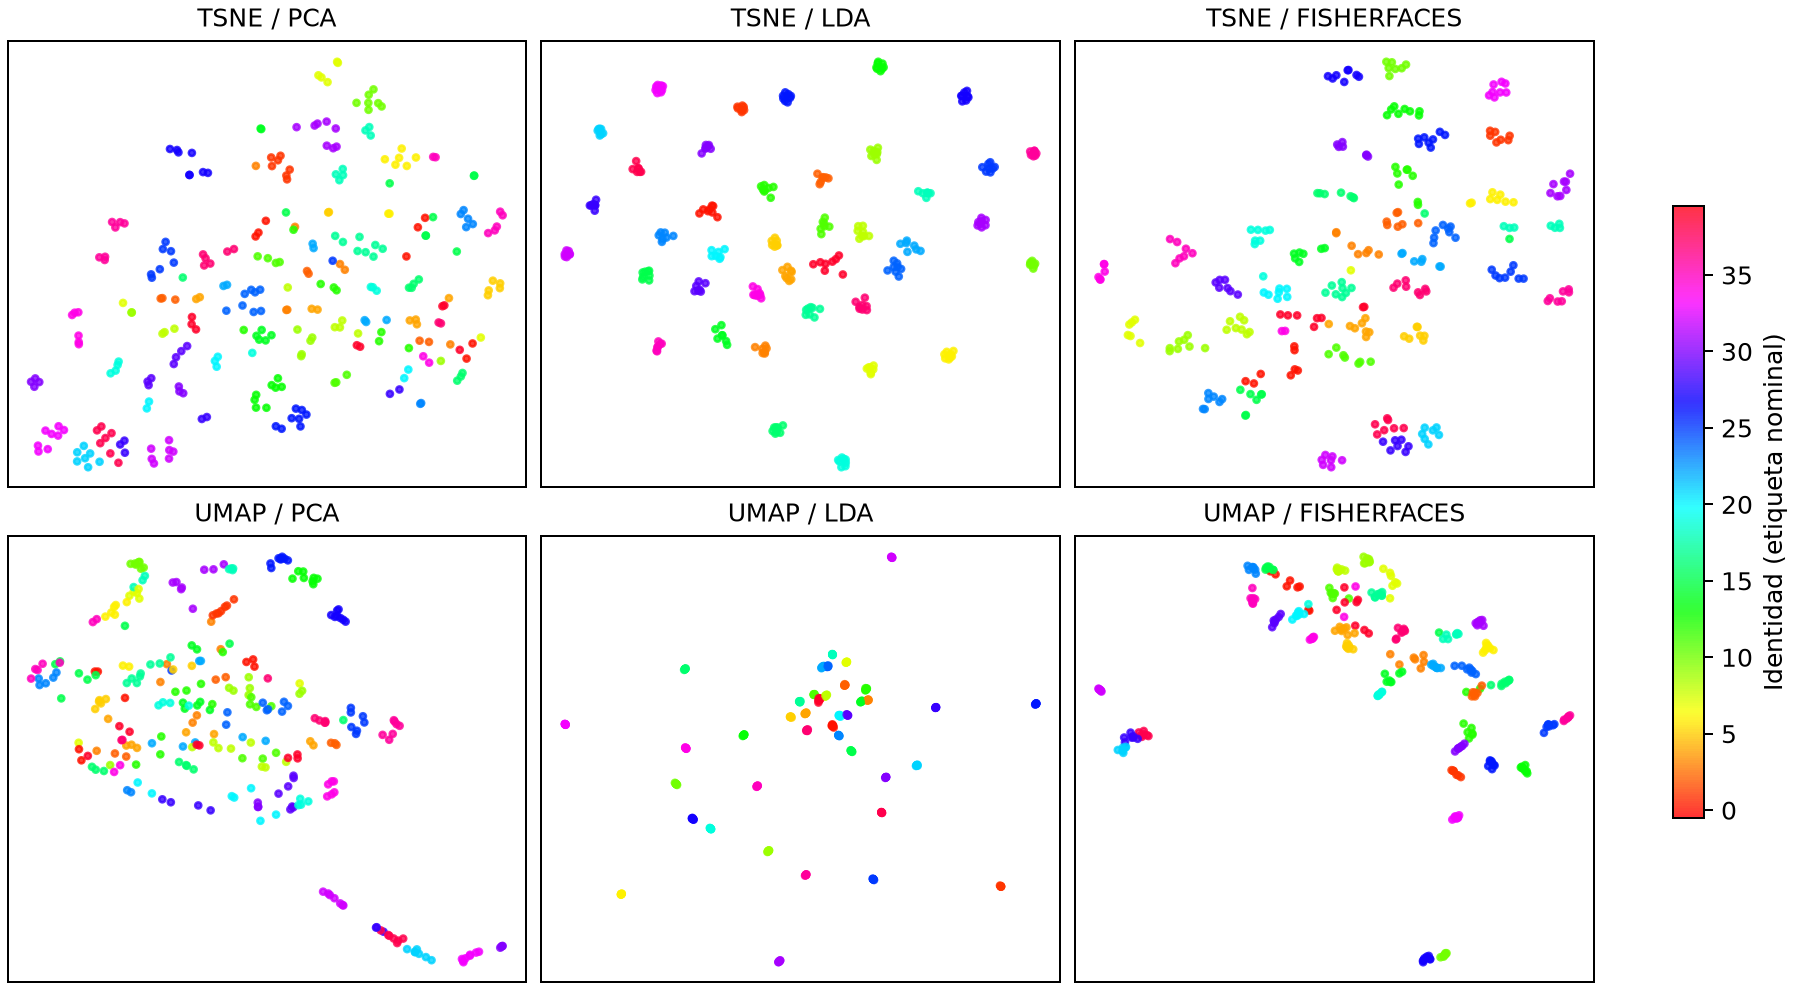

### LFW: 3 representaciones × 2 mapas

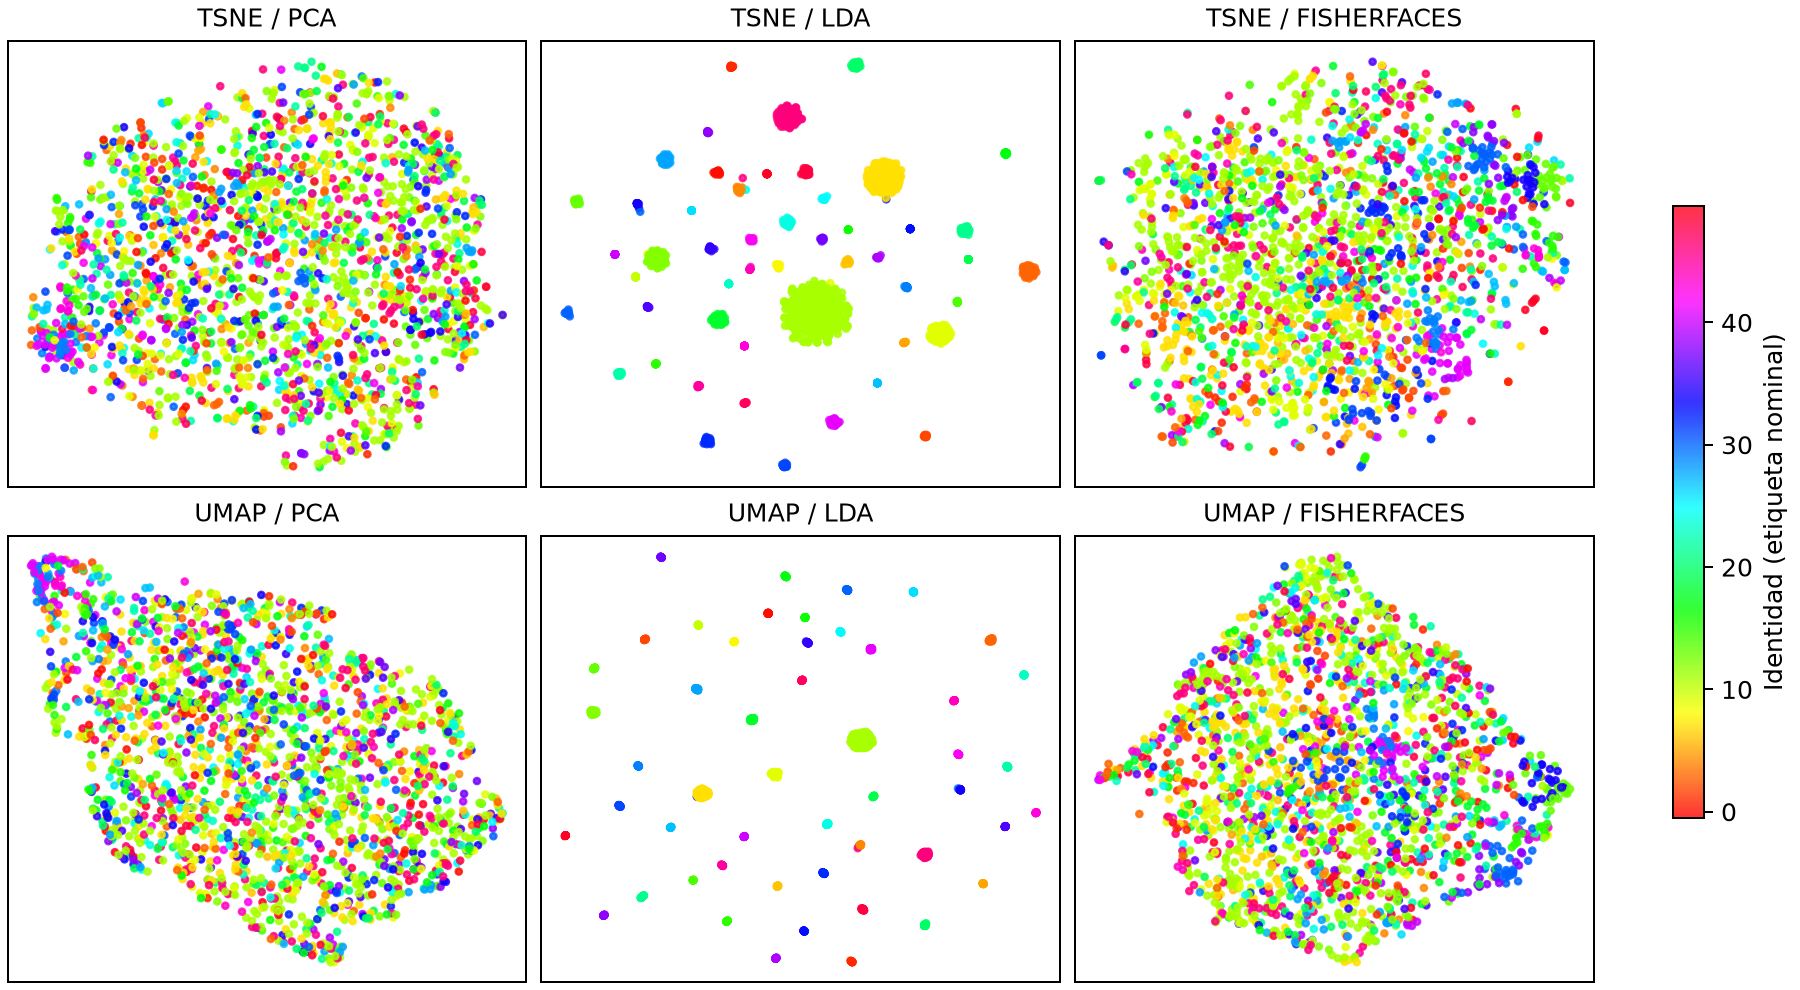

In [6]:
for dataset in ["olivetti", "lfw"]:
    display(Markdown(f"### {dataset.upper()}: 3 representaciones × 2 mapas"))
    display(Image(filename=str(DIR_FIGURAS / f"mapas_comparados_{dataset}.png"), width=1050))


## 7. Confusiones y fotografías de error
Para comparar los clasificadores se fija PCA(20), sin seleccionar esta configuración
por sus puntuaciones de TEST. En las matrices, filas = real y columnas = predicha.
Las matrices de las restantes 48 combinaciones también están en `figuras/`.

Se muestra el primer error de cada clasificador según el índice original ordenado.
A la derecha se incluye una fotografía de TRAIN de la identidad predicha (la más
cercana en píxeles). Es una referencia para inspección, no la regla del clasificador
ni una explicación causal. Pose, expresión o iluminación son hipótesis visuales
que necesitarían un experimento adicional para comprobarse.

### OLIVETTI

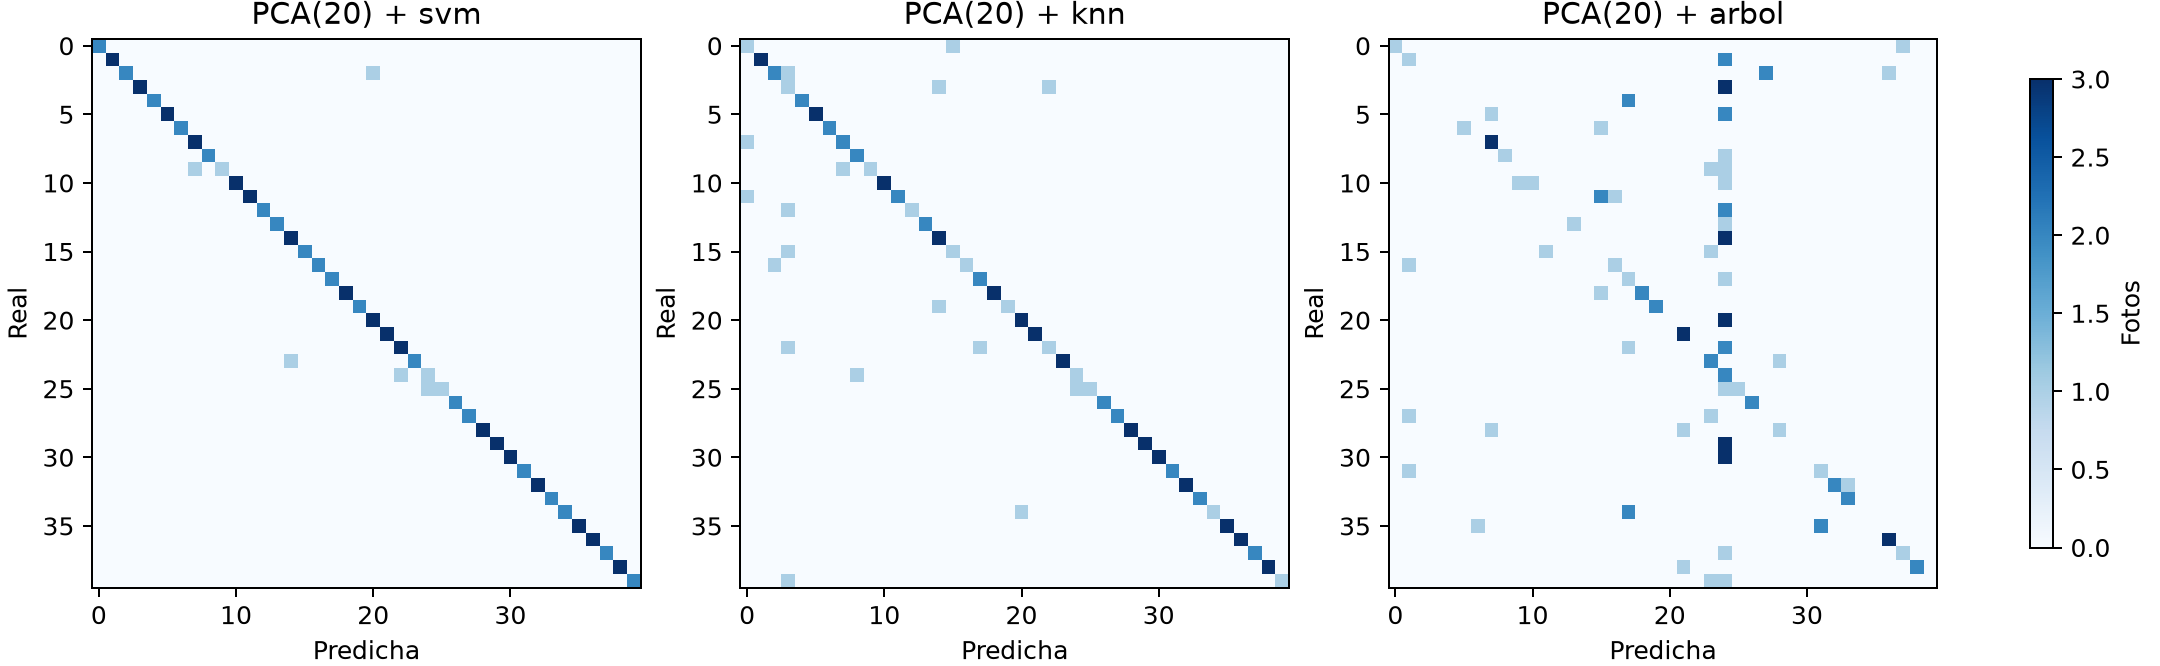

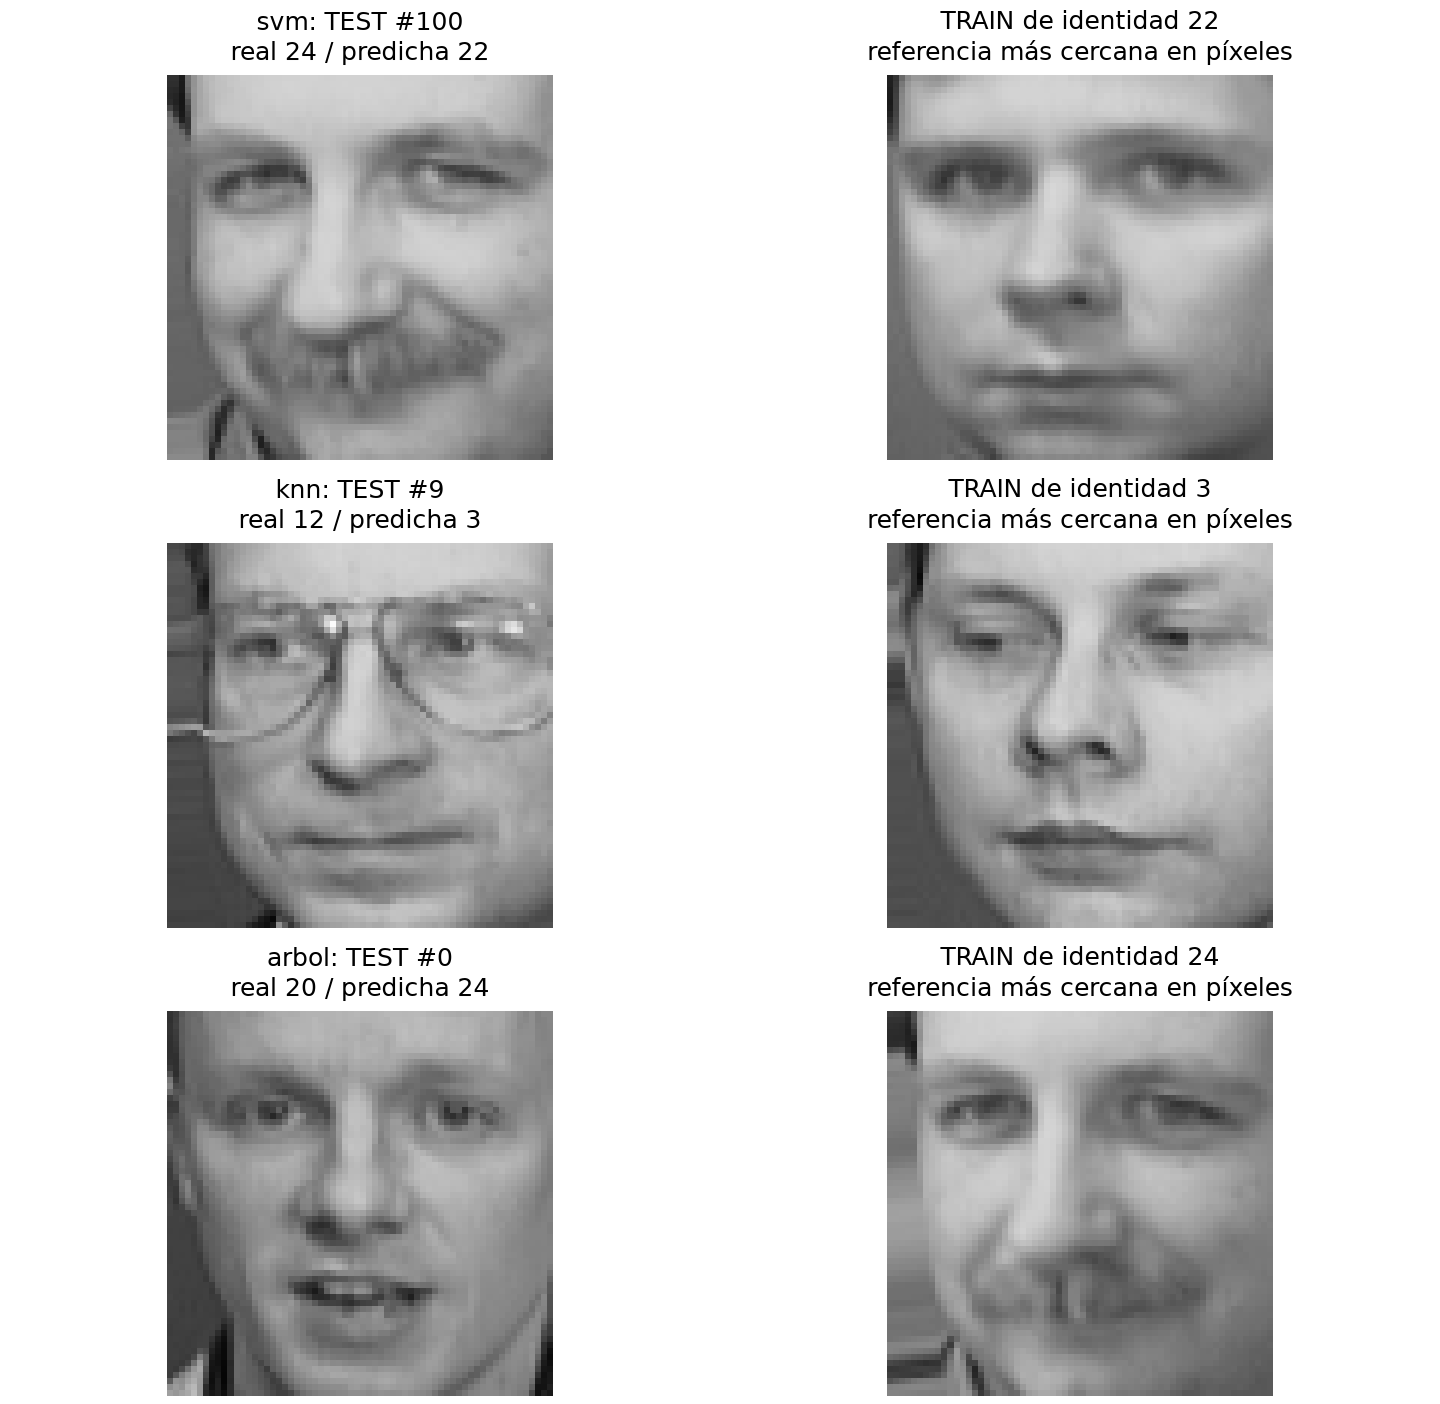

,modelo,test_posicion,test_indice_original,real,predicha,nombre_real,nombre_predicho
0,svm,28,100,24,22,Identidad 24,Identidad 22
1,knn,2,9,12,3,Identidad 12,Identidad 3
2,arbol,0,0,20,24,Identidad 20,Identidad 24


Pares dirigidos real → predicha comunes a los tres clasificadores (PCA20): [[25, 24]]


### LFW

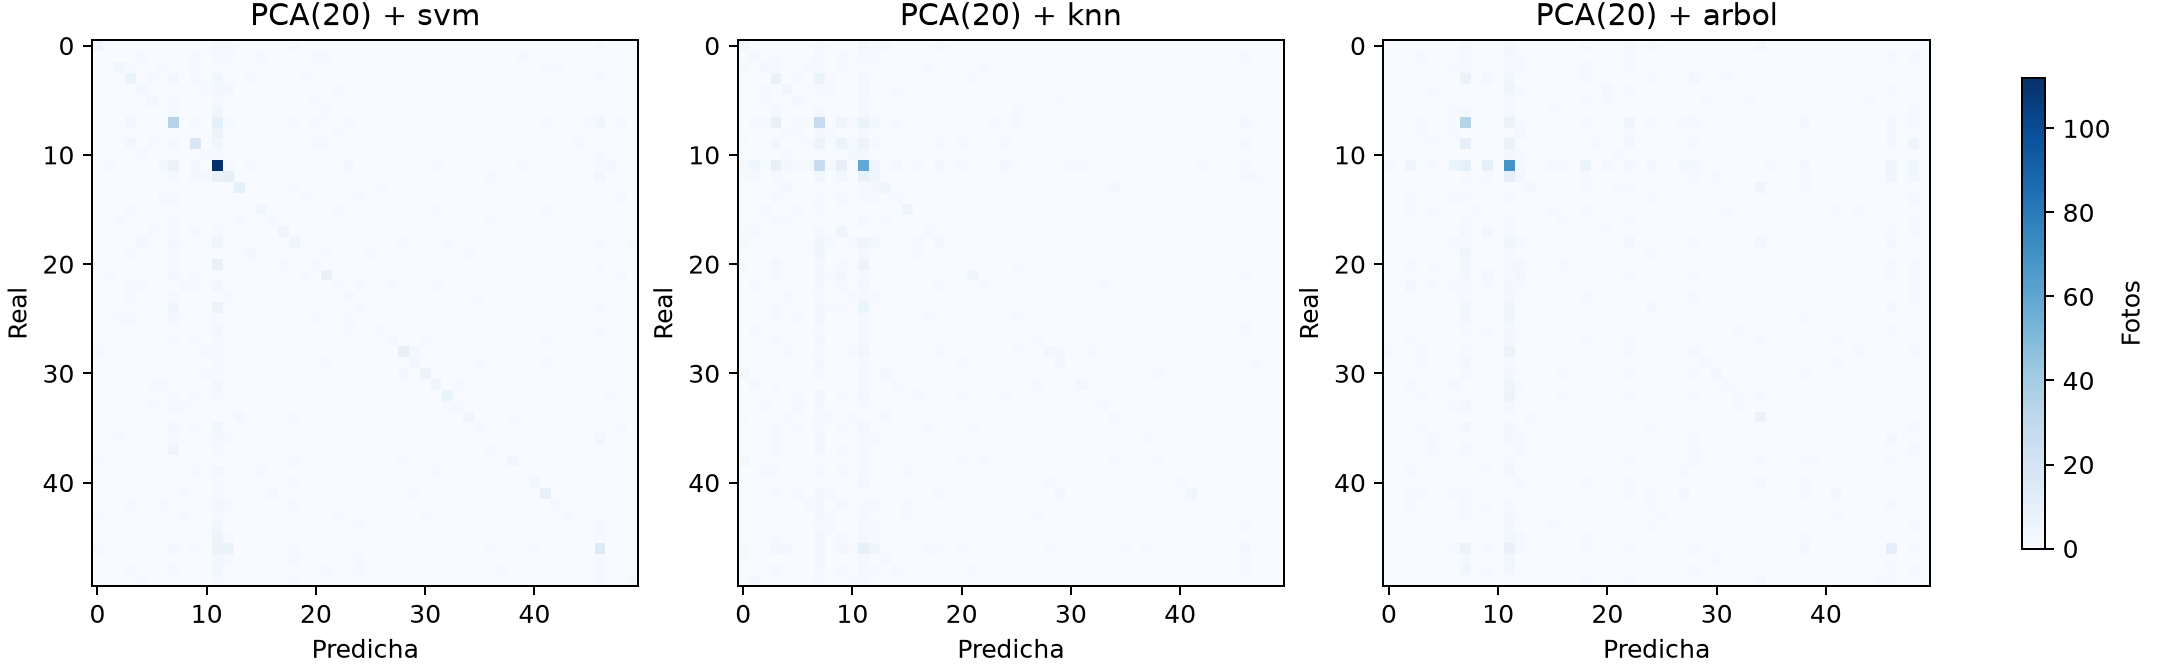

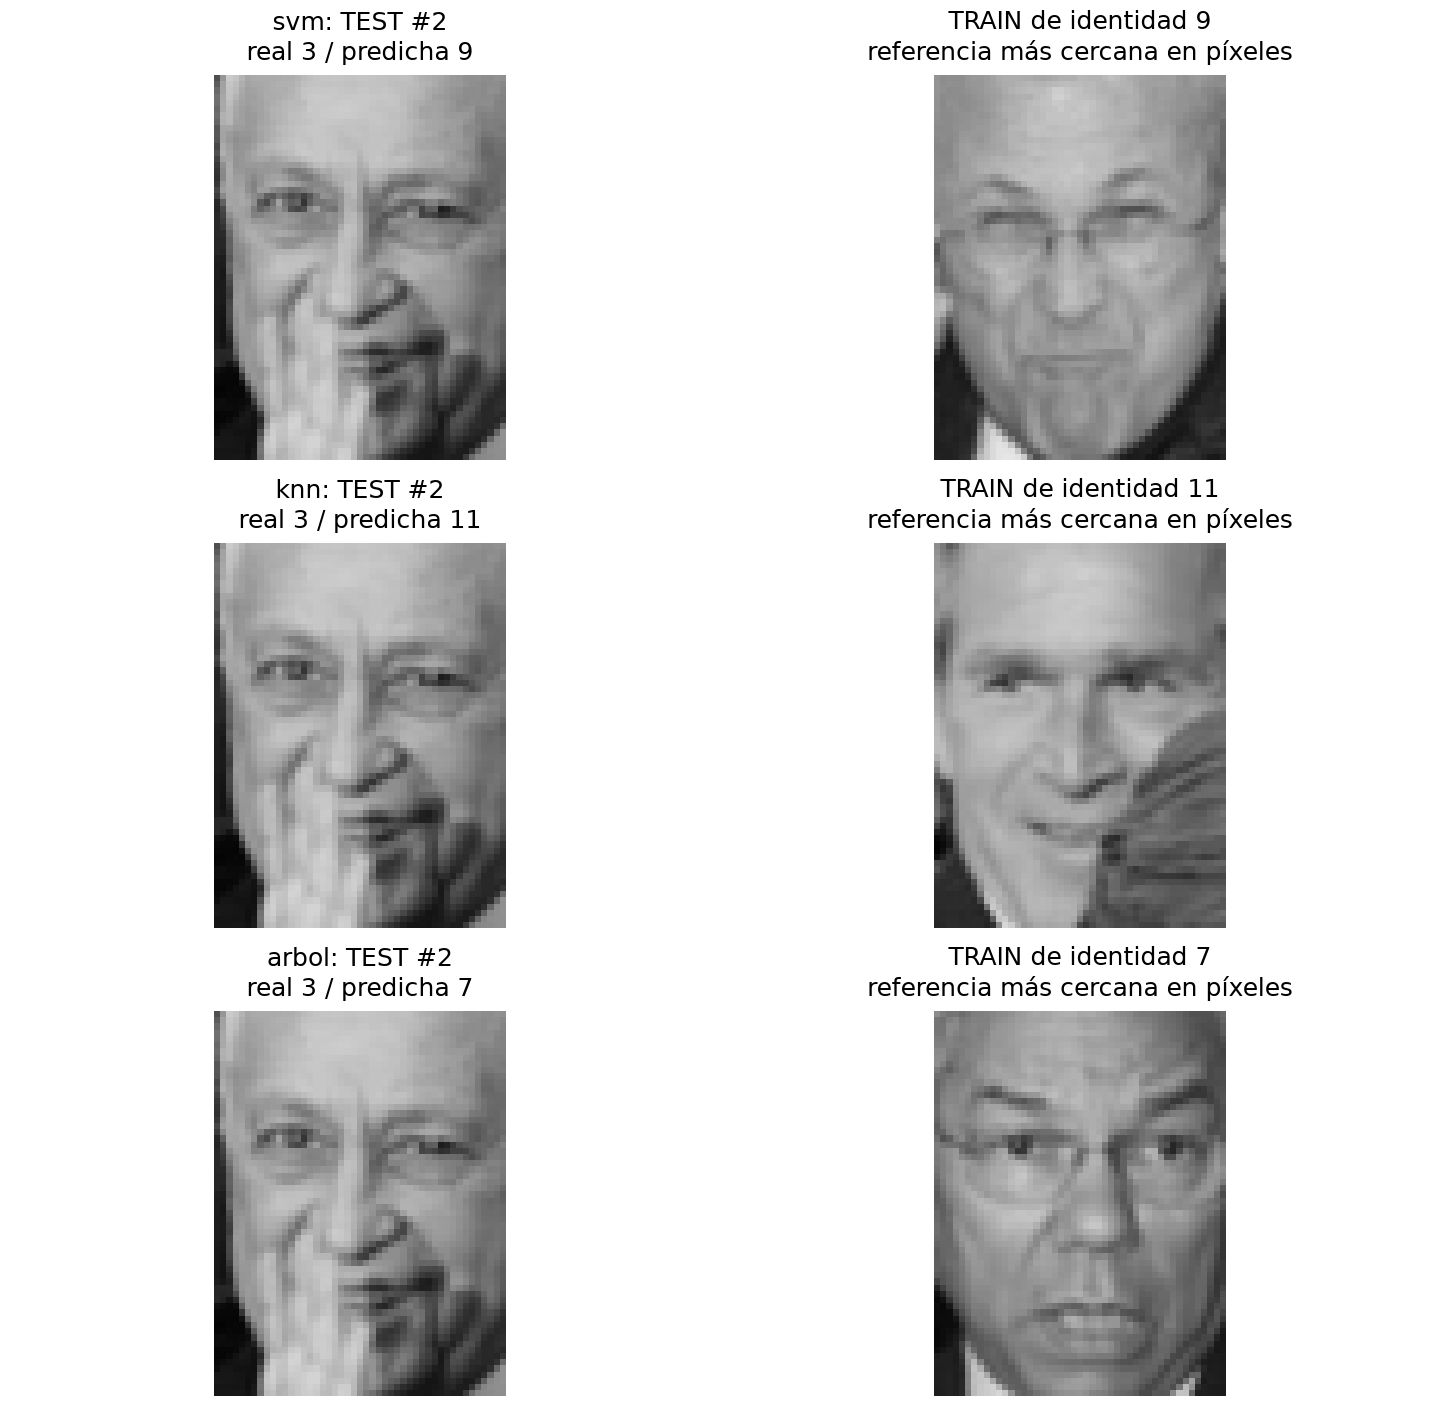

,modelo,test_posicion,test_indice_original,real,predicha,nombre_real,nombre_predicho
0,svm,0,2,3,9,Ariel Sharon,Donald Rumsfeld
1,knn,0,2,3,11,Ariel Sharon,George W Bush
2,arbol,0,2,3,7,Ariel Sharon,Colin Powell


Pares dirigidos real → predicha comunes a los tres clasificadores (PCA20): [[0, 11], [0, 18], [1, 11], [1, 12], [2, 6], [3, 7], [3, 11], [4, 11], [5, 11], [6, 7], [6, 11], [7, 3], [7, 11], [7, 12], [7, 46], [9, 7], [9, 11], [10, 11], [11, 6], [11, 7], [11, 9], [11, 12], [11, 46], [12, 7], [12, 9], [12, 11], [12, 46], [14, 7], [17, 7], [17, 9], [18, 7], [18, 11], [19, 7], [20, 7], [20, 11], [21, 7], [21, 9], [22, 9], [22, 11], [23, 7], [24, 7], [24, 11], [25, 7], [25, 11], [26, 11], [26, 46], [27, 11], [28, 11], [29, 11], [30, 11], [31, 11], [32, 11], [33, 7], [34, 13], [35, 7], [35, 11], [36, 11], [36, 12], [37, 7], [39, 9], [39, 11], [42, 11], [43, 11], [44, 11], [45, 11], [45, 12], [46, 7], [46, 9], [46, 11], [46, 12], [46, 18], [47, 11], [47, 46], [48, 7], [48, 11], [48, 46]]


,dataset,embedding,d,modelo,real,predicha,cantidad
464,lfw,pca,20,knn,11,7,26
1900,lfw,lda,20,arbol,11,41,19
2483,lfw,fisherfaces,20,knn,11,7,18
2765,lfw,fisherfaces,20,arbol,11,46,12
2660,lfw,fisherfaces,20,knn,46,11,11
2224,lfw,fisherfaces,20,svm,7,11,11
2485,lfw,fisherfaces,20,knn,11,9,10
755,lfw,pca,20,arbol,11,9,10
771,lfw,pca,20,arbol,12,11,10
194,lfw,pca,20,svm,7,11,10


In [7]:
for dataset in ["olivetti", "lfw"]:
    display(Markdown(f"### {dataset.upper()}"))
    display(Image(filename=str(DIR_FIGURAS / f"confusiones_comparadas_{dataset}.png"), width=1050))
    display(Image(filename=str(DIR_FIGURAS / f"errores_{dataset}.png"), width=750))
    display(pd.DataFrame(resumen["datasets"][dataset]["ejemplos_errores_pca20"]))
    print("Pares dirigidos real → predicha comunes a los tres clasificadores (PCA20):",
          resumen["datasets"][dataset]["pares_comunes_tres_clasificadores_pca20"])
pares = pd.read_csv(DIR_RESULTADOS / "confusiones_pares.csv")
display(pares.sort_values("cantidad", ascending=False).head(20))


## 8. Respuestas a las preguntas del laboratorio
La siguiente salida contrasta dimensiones y representaciones con los valores
calculados, sin convertir el máximo de TEST en una selección validada.

In [8]:
for dataset in ["olivetti", "lfw"]:
    t = tabla[tabla.dataset == dataset]
    display(Markdown(f"### {dataset.upper()}"))
    display(t.pivot(index=["modelo", "d"], columns="embedding", values="macro_f1"))
    pca_svm = t[(t.embedding == "pca") & (t.modelo == "svm")].sort_values("d")
    print("PCA + SVM; d, macro-F1, tiempo fit+predict:")
    print(pca_svm[["d", "macro_f1", "tiempo_s"]].to_string(index=False))
    f = t[t.embedding == "fisherfaces"].set_index(["modelo", "d"])
    p = t[t.embedding == "pca"].set_index(["modelo", "d"])
    delta = f.macro_f1 - p.macro_f1
    print(f"Fisherfaces frente a PCA en 9 pares: mejora {(delta>1e-6).sum()}, "
          f"empata {(abs(delta)<=1e-6).sum()}, empeora {(delta < -1e-6).sum()}.")
    display(t.loc[t.macro_f1.idxmax(), ["embedding", "d", "modelo", "accuracy", "macro_f1", "tiempo_s"]])


### OLIVETTI

embedding  fisherfaces       lda       pca
modelo d                                  
arbol  10     0.398790  0.302679  0.266705
       20     0.293364  0.262921  0.340456
       30     0.250032  0.297776  0.302976
knn    10     0.779524  0.990000  0.772679
       20     0.937024  0.968095  0.825734
       30     0.941429  0.969524  0.831190
svm    10     0.896190  0.980000  0.851548
       20     0.978095  0.969524  0.946548
       30     0.959524  0.957619  0.979524

PCA + SVM; d, macro-F1, tiempo fit+predict:
 d  macro_f1  tiempo_s
10  0.851548    0.2109
20  0.946548    0.2162
30  0.979524    0.2169
Fisherfaces frente a PCA en 9 pares: mejora 6, empata 0, empeora 3.


embedding      lda
d               10
modelo         knn
accuracy      0.99
macro_f1      0.99
tiempo_s     0.007
Name: 4, dtype: object

### LFW

embedding  fisherfaces       lda       pca
modelo d                                  
arbol  10     0.120056  0.053752  0.065241
       20     0.172499  0.039259  0.082750
       30     0.152440  0.043343  0.088935
knn    10     0.124279  0.095169  0.125886
       20     0.258347  0.159347  0.149763
       30     0.308251  0.169298  0.192730
svm    10     0.176450  0.103805  0.172970
       20     0.320795  0.157062  0.321716
       30     0.395485  0.176892  0.383481

PCA + SVM; d, macro-F1, tiempo fit+predict:
 d  macro_f1  tiempo_s
10  0.172970    7.7589
20  0.321716    7.0327
30  0.383481    4.2465
Fisherfaces frente a PCA en 9 pares: mejora 7, empata 0, empeora 2.


embedding    fisherfaces
d                     30
modelo               svm
accuracy         0.48415
macro_f1        0.395485
tiempo_s          3.1451
Name: 51, dtype: object

## Interpretación de la ejecución adjunta

- **Varianza y reconocimiento:** en Olivetti, PCA conserva 65,5%, 76,5% y 82,2% de varianza con 10, 20 y 30 componentes. Sin embargo, el árbol con PCA baja su macro-F1 de 0,340456 a 0,302976 entre 20 y 30: conservar más variación no asegura reconocer mejor.
- **Fisherfaces frente a PCA:** mejora en 6 de 9 pares equivalentes de Olivetti y 7 de 9 en LFW; empeora en los restantes. La mejora depende del clasificador y la dimensión.
- **Dimensión y costo:** LDA(10) + k-NN alcanza el máximo descriptivo en Olivetti (accuracy y macro-F1 0,990; 0,0070 s del clasificador), usando una representación compacta. En LFW, Fisherfaces + SVM aumenta macro-F1 de 0,320795 con d=20 a 0,395485 con d=30, con tiempos de 3,0703 y 3,1451 s. Son candidatos para validar dentro de TRAIN; TEST no permite una elección validada de parámetros.
- **Confusiones:** los tres clasificadores con PCA(20) comparten el par dirigido 25 → 24 en Olivetti y 76 pares dirigidos en LFW, pero sus conjuntos de errores no son idénticos. El CSV de pares conserva todos los casos.
- **Mapas y TEST:** LDA genera grupos compactos en TRAIN de LFW, pero LDA(30) + SVM obtiene macro-F1 0,176892 en TEST, frente a 0,395485 con Fisherfaces(30) + SVM. La compactación supervisada no demuestra generalización. UMAP advirtió que el grafo de LDA en LFW no era conexo: su organización global debe interpretarse con cautela.
- **Errores concretos:** PCA(20) + SVM confunde la foto Olivetti #100 (real 24, predicha 22) y LFW #2 (real 3, predicha 9). Las fotografías y las referencias permiten formular hipótesis sobre pose, gesto o iluminación, sin demostrar la causa del error.

Los tiempos excluyen el ajuste de las representaciones; una sola partición y una medición temporal no permiten afirmar significancia ni estabilidad. Las cifras corresponden a las versiones y a la ejecución adjuntas.


**Interpretación y límites.** Una mayor dimensión preserva más variación, pero
también puede introducir variación irrelevante; se debe contrastar con macro-F1.
Fisherfaces depende del clasificador y del tamaño intermedio PCA, de modo que no
se presupone una mejora universal. Para escoger un modelo se requiere validación
interna con la representación reajustada dentro de cada fold; aquí se describen
configuraciones fijas. El costo medido no compara el tiempo completo de PCA y LDA.

Olivetti y LFW son experimentos separados. La diferencia entre sus métricas no
aisla causalmente el efecto de pose o iluminación: también cambian identidades,
balance y número de muestras. El sistema evalúa identidades conocidas, sin rechazo
de desconocidos. No permite inferir desempeño en poblaciones nuevas ni justifica
vigilancia. Se usan solo fotografías públicas de los datasets y no se agregan
fotografías personales ni se infieren atributos sensibles.

## 9. Comprobación de la interfaz y reproducibilidad
La interfaz debe usar `predict`, igual que las métricas; la probabilidad mostrada
es la de esa identidad. SVM puede asignar su mayor probabilidad a otra clase.
Se comprueba el servicio para todas las fotografías y combinaciones Olivetti;
esto no reemplaza la inspección visual manual de Streamlit.

In [9]:
from src.interfaz.servicio import ServicioReconocimiento
servicio = ServicioReconocimiento()
verificadas = 0
diferencias_svm = 0
for emb in ["pca", "lda", "fisherfaces"]:
    for d in [10, 20, 30]:
        for mod in ["svm", "knn", "arbol"]:
            bundle = servicio._obtener_bundle(emb, mod, d)
            Z = bundle["extractor"].transform(servicio.particion.X_test)
            modelo = bundle["clasificador"]
            pred = modelo.predict(Z)
            if mod == "svm":
                orden_prob = modelo.classes_[np.argmax(modelo.predict_proba(Z), axis=1)]
                diferencias_svm += int(np.sum(orden_prob != pred))
            for i in range(len(pred)):
                r = servicio.predecir(i, emb, mod, d)
                assert r.identidad_predicha == int(pred[i])
                assert r.acierto == (int(pred[i]) == int(servicio.particion.y_test[i]))
                verificadas += 1
print("Predicciones del servicio verificadas:", verificadas)
print("Diferencias predict vs argmax(predict_proba) en SVM:", diferencias_svm)
resumen["verificacion_servicio"] = {"predicciones": verificadas,
    "discrepancias_svm_predict_vs_argmax_proba": diferencias_svm}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")


Predicciones del servicio verificadas: 2700
Diferencias predict vs argmax(predict_proba) en SVM: 36


10345

Para ejecutar las pruebas se utiliza `python -m unittest discover -s tests -v`; la interfaz se inicia con `streamlit run app.py`.

El informe se entrega por separado. Los datos descargados, modelos y figuras se regeneran y están excluidos del seguimiento de Git.

## Referencias
- Bekios Calfa, J. (2026). *Machine Learning, Laboratorio 02: Embeddings faciales lineales*. Material docente.
- Belhumeur, P. N., Hespanha, J. P. y Kriegman, D. J. (1997). *Eigenfaces vs. Fisherfaces*. https://doi.org/10.1109/34.598228
- van der Maaten, L. y Hinton, G. (2008). *Visualizing Data using t-SNE*. https://jmlr.org/papers/v9/vandermaaten08a.html
- McInnes, L., Healy, J. y Melville, J. (2018). *UMAP*. https://arxiv.org/abs/1802.03426
- scikit-learn: [Olivetti](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html), [LFW](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [LDA](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html), [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).
- Fotografías: AT&T Laboratories Cambridge (Olivetti); Labeled Faces in the Wild, University of Massachusetts Amherst (LFW), distribuidas mediante scikit-learn.